# 06 · Unsupervised learning

**CSE274 Unit VI.** What unsupervised learning is for and how it differs from supervised learning; distance metrics; partitioning clustering (K-Means, K-Medoids); hierarchical clustering, dendrograms and linkage; density-based clustering (DBSCAN); anomaly detection; and evaluating clusters with inertia, the silhouette score and the Davies–Bouldin index.

The labels are put aside. The question becomes: *what natural groups of fields exist, and which fields look wrong?*

In [1]:
try:
    import irrigate
except ImportError:  # running on Kaggle
    %pip install -q git+https://github.com/LuShadowX/Irrigate
    import irrigate

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from irrigate import data, plotting
plotting.setup()

df = data.sample(12_000, seed=8)
y = df[data.TARGET].cat.codes.to_numpy()
signal = ["Soil_Moisture", "Temperature_C", "Wind_Speed_kmh", "Rainfall_mm"]
X = StandardScaler().fit_transform(df[signal])

## 1. Introduction to unsupervised learning

### Role of unsupervised learning
Finding structure without labels: **segmentation** (groups of similar fields that could share an irrigation plan), **compression** (PCA, notebook 02), **anomaly detection** (faulty sensors, unusual fields), and **exploration** before any labels exist.

### Supervised vs unsupervised

| | Supervised | Unsupervised |
|---|---|---|
| Data | features and labels | features only |
| Goal | predict the label | discover structure |
| Evaluation | compare with the true labels | internal measures (silhouette, inertia) or usefulness |
| Examples here | notebooks 03–05 | this notebook |

The clustering below uses the four standardised features the EDA found informative: soil moisture, temperature, wind speed and rainfall.

## 2. Distance metrics

Clustering is only as good as its idea of "close".
- **Euclidean** (L2): straight-line distance, √Σ(aᵢ − bᵢ)². The default.
- **Manhattan** (L1): Σ|aᵢ − bᵢ|, distance along the axes. Less dominated by one large difference.
- **Cosine distance:** 1 − cos(angle between the vectors). Ignores length, compares direction; the standard for text and embeddings.

These are the same three metrics as in `sentence-transformers`, where in August 2026 I fixed Euclidean and Manhattan similarity to work when one input is a sparse tensor and the other dense ([PR #3906](https://github.com/huggingface/sentence-transformers/pull/3906), merged). Here they are written from scratch, checked against SciPy, and compared on two fields:

In [2]:
from scipy.spatial.distance import cdist

def euclidean(a, b):
    return np.sqrt(((a - b) ** 2).sum(-1))

def manhattan(a, b):
    return np.abs(a - b).sum(-1)

def cosine_distance(a, b):
    return 1 - (a * b).sum(-1) / (np.linalg.norm(a, axis=-1) * np.linalg.norm(b, axis=-1))

a, b = X[0], X[1]
pd.DataFrame({
    "from scratch": [euclidean(a, b), manhattan(a, b), cosine_distance(a, b)],
    "scipy": [cdist([a], [b], "euclidean")[0, 0], cdist([a], [b], "cityblock")[0, 0], cdist([a], [b], "cosine")[0, 0]],
}, index=["Euclidean", "Manhattan", "cosine"]).round(6)

,from scratch,scipy
Euclidean,1.127960,1.127960
Manhattan,2.066219,2.066219
cosine,0.163500,0.163500


### Choosing an appropriate metric
Different metrics disagree about who is whose nearest neighbour. Out of 1,000 fields, how often do two metrics pick the same nearest neighbour, and how often is that neighbour of the same class?

In [3]:
P = X[:1000]
nn = {}
for name, metric in [("Euclidean", "euclidean"), ("Manhattan", "cityblock"), ("cosine", "cosine")]:
    D = cdist(P, P, metric)
    np.fill_diagonal(D, np.inf)
    nn[name] = D.argmin(1)
agree = pd.DataFrame({m1: {m2: np.mean(nn[m1] == nn[m2]) for m2 in nn} for m1 in nn})
same_class = pd.Series({m: np.mean(y[:1000][nn[m]] == y[:1000]) for m in nn}, name="nearest neighbour has the same class")
print(agree.round(3))
same_class.round(3).to_frame()

           Euclidean  Manhattan  cosine
Euclidean      1.000      0.798   0.484
Manhattan      0.798      1.000   0.461
cosine         0.484      0.461   1.000


,nearest neighbour has the same class
Euclidean,0.650
Manhattan,0.665
cosine,0.671


Euclidean and Manhattan mostly agree; cosine often picks a different neighbour because it ignores how *far* a field is from the average and only looks at the direction of its deviation. For measurements on a common scale, Euclidean or Manhattan fits; for embeddings and text, cosine.

## 3. Partitioning clustering algorithms

### K-Means
Choose k centres; assign every point to its nearest centre; move each centre to the mean of its points; repeat until nothing changes. It minimises the **inertia** (within-cluster sum of squared distances). Written out in NumPy and compared with scikit-learn:

In [4]:
from sklearn.cluster import KMeans

def kmeans(X, k, iters=100, seed=0):
    rng = np.random.default_rng(seed)
    centres = X[rng.choice(len(X), k, replace=False)]
    history = []
    for _ in range(iters):
        labels = euclidean(X[:, None, :], centres[None, :, :]).argmin(1)
        new = np.array([X[labels == j].mean(0) for j in range(k)])
        history.append(((X - centres[labels]) ** 2).sum())
        if np.allclose(new, centres):
            break
        centres = new
    return labels, centres, history

labels_np, centres_np, hist = kmeans(X, 4)
sk = KMeans(4, n_init=10, random_state=0).fit(X)
print(f"from scratch: inertia {hist[-1]:,.1f} after {len(hist)} iterations")
print(f"scikit-learn: inertia {sk.inertia_:,.1f} (best of 10 starts)")
print("one random start finds a slightly worse local minimum, which is why k-means is usually run several times")

from scratch: inertia 29,068.1 after 74 iterations
scikit-learn: inertia 28,705.5 (best of 10 starts)
one random start finds a slightly worse local minimum, which is why k-means is usually run several times


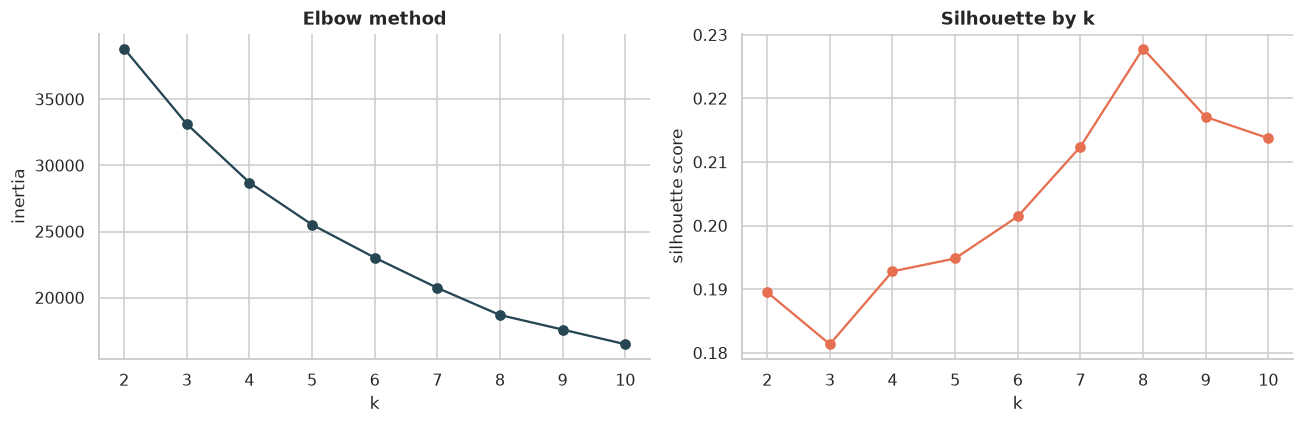

In [5]:
inertia, sil = [], []
from sklearn.metrics import silhouette_score
ks = range(2, 11)
for k in ks:
    km = KMeans(k, n_init=10, random_state=0).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_, sample_size=4000, random_state=0))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(ks), inertia, "o-", color=plotting.ACCENT)
axes[0].set(xlabel="k", ylabel="inertia", title="Elbow method")
axes[1].plot(list(ks), sil, "o-", color="#e76f51")
axes[1].set(xlabel="k", ylabel="silhouette score", title="Silhouette by k")
fig.tight_layout()
plotting.save("i06-elbow")
plt.show()

Neither curve has a sharp elbow or a clear peak: the features are close to uniform and independent, so the fields don't form tight, separate blobs. That is an honest finding about this data, and K-Means still gives a useful *segmentation*. With k = 4, the segments differ strongly in irrigation need, even though K-Means never saw the labels:

In [6]:
km4 = KMeans(4, n_init=10, random_state=0).fit(X)
seg = df.assign(segment=km4.labels_)
profile = seg.groupby("segment")[signal].mean().round(1)
profile["fields"] = seg["segment"].value_counts().sort_index()
profile["share High"] = seg.groupby("segment")[data.TARGET].apply(lambda t: (t == "High").mean()).round(3)
profile["share Low"] = seg.groupby("segment")[data.TARGET].apply(lambda t: (t == "Low").mean()).round(3)
profile.sort_values("share High")

,Soil_Moisture,Temperature_C,Wind_Speed_kmh,Rainfall_mm,fields,share High,share Low
segment,,,,,,,
0,37.5,18.6,5.7,1517.3,2976,0.000,0.824
2,51.5,25.7,15.4,1440.0,3060,0.002,0.656
1,39.8,35.0,5.5,1537.4,2955,0.007,0.643
3,20.6,28.8,14.6,1369.2,3009,0.124,0.229


### K-Medoids (PAM: partitioning around medoids)
Like K-Means, but each centre must be an actual data point (a **medoid**) and any distance can be used, which makes it robust to outliers and usable with Manhattan or cosine distance. PAM swaps a medoid with a non-medoid whenever the swap lowers the total distance. scikit-learn doesn't include it, so here it is from scratch on 1,500 fields, with Manhattan distance:

In [7]:
def k_medoids(D, k, iters=50, seed=0):
    rng = np.random.default_rng(seed)
    medoids = rng.choice(len(D), k, replace=False)
    cost = D[:, medoids].min(1).sum()
    for _ in range(iters):
        improved = False
        for i in range(k):
            for cand in rng.choice(len(D), 60, replace=False):   # try a random subset of swaps each round
                if cand in medoids:
                    continue
                trial = medoids.copy()
                trial[i] = cand
                c = D[:, trial].min(1).sum()
                if c < cost:
                    medoids, cost, improved = trial, c, True
        if not improved:
            break
    return D[:, medoids].argmin(1), medoids, cost

Xm = X[:1500].copy()
Xm[:15] = np.random.default_rng(3).normal(0, 9, (15, Xm.shape[1]))    # 15 scattered extreme outliers
D = cdist(Xm, Xm, "cityblock")
lab_med, medoids, cost = k_medoids(D, 4)
km_out = KMeans(4, n_init=10, random_state=0).fit(Xm)
print("K-Medoids centres are real fields:", medoids.tolist(), "· none of them is an outlier:", not any(m < 15 for m in medoids))
print("K-Means: largest centre coordinate", round(np.abs(km_out.cluster_centers_).max(), 2), "(pulled by the outliers)")
print("K-Medoids: largest medoid coordinate", round(np.abs(Xm[medoids]).max(), 2))

K-Medoids centres are real fields: [1187, 643, 832, 710] · none of them is an outlier: True
K-Means: largest centre coordinate 15.75 (pulled by the outliers)
K-Medoids: largest medoid coordinate 1.19


## 4. Hierarchical clustering

### Types
**Agglomerative** (bottom-up): start with every point as its own cluster and repeatedly merge the two closest. **Divisive** (top-down): start with one cluster and split. Agglomerative is the common one.

### Linkage criteria
How "distance between two clusters" is defined: **single** (closest pair), **complete** (farthest pair), **average** (mean of all pairs), **Ward** (merge that increases within-cluster variance least).

### The dendrogram
The full merge history as a tree; cutting it at a height gives a flat clustering.

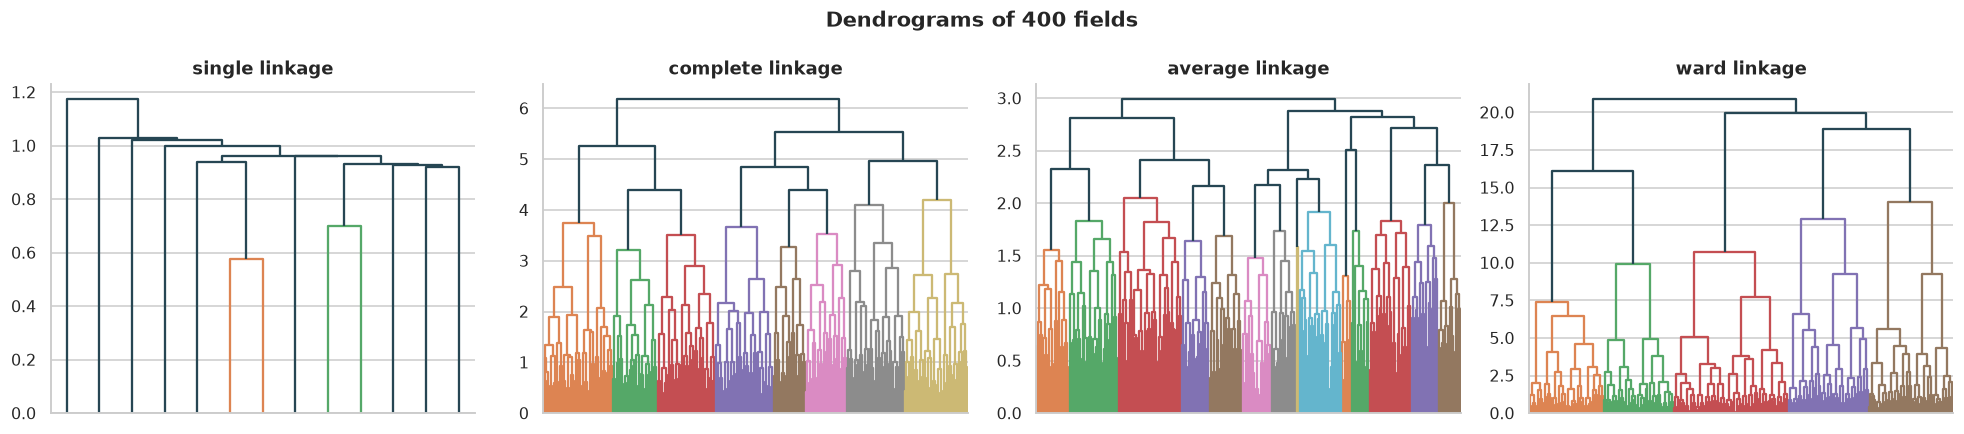

,cluster sizes when cut into 4
single,"[397, 1, 1, 1]"
complete,"[126, 125, 97, 52]"
average,"[173, 126, 82, 19]"
ward,"[111, 111, 90, 88]"


In [8]:
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage

sub = X[:400]
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=False)
sizes = {}
for ax, method in zip(axes, ["single", "complete", "average", "ward"]):
    Z = linkage(sub, method=method)
    dendrogram(Z, ax=ax, no_labels=True, color_threshold=None, above_threshold_color=plotting.ACCENT, truncate_mode="level", p=8)
    ax.set_title(f"{method} linkage")
    sizes[method] = np.sort(np.bincount(fcluster(Z, 4, criterion="maxclust"))[1:])[::-1].tolist()
fig.suptitle("Dendrograms of 400 fields", fontweight="bold")
fig.tight_layout()
plotting.save("i06-dendrograms")
plt.show()
pd.Series(sizes, name="cluster sizes when cut into 4").to_frame()

Single linkage "chains": it makes one giant cluster and a few singletons. Ward produces balanced, compact groups, which is why it is the usual default.

## 5. Density-based clustering (DBSCAN)

### Key concepts
Two parameters: a radius **ε** and **minPts**. A cluster is a dense region; anything in a sparse region is noise. No need to choose k, and clusters can have any shape.

### Point classifications
**Core** points have at least minPts neighbours within ε; **border** points are within ε of a core point but have fewer neighbours; **noise** points are neither. On the irrigation features, which have no dense blobs, DBSCAN mostly finds one big cluster. Its strength shows on data that *does* have shape, such as the dry-and-hot corner of moisture–temperature space, where High fields concentrate:

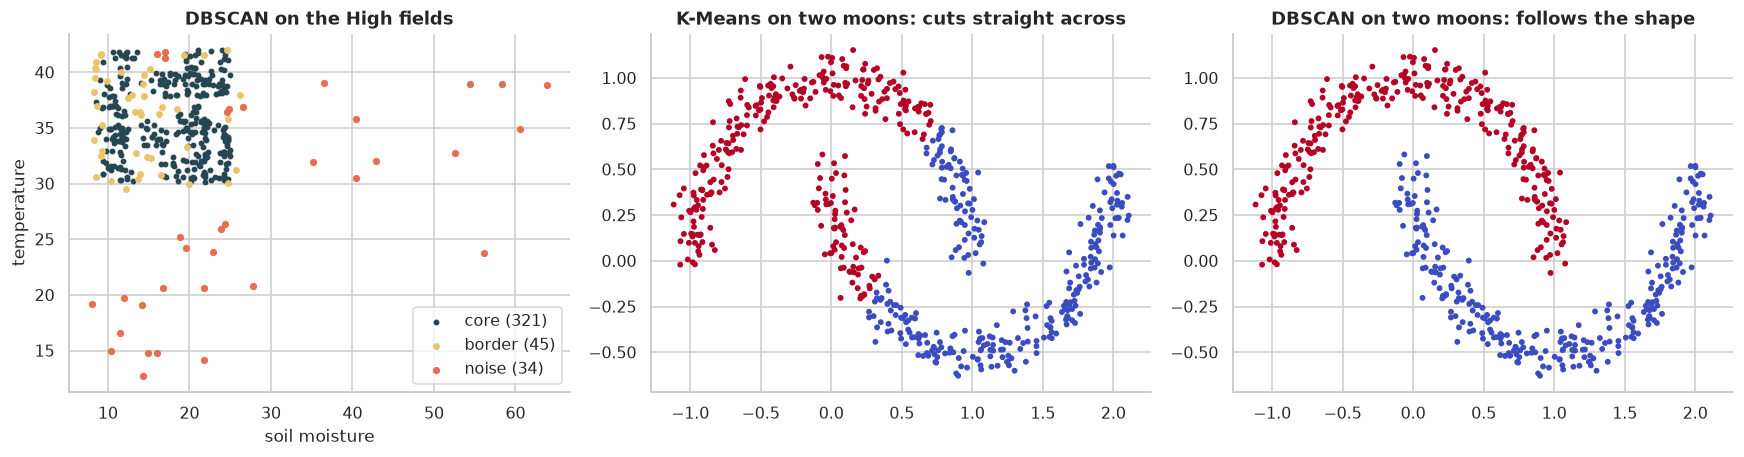

DBSCAN on the High fields: {'core': 321, 'border': 45, 'noise': 34} · clusters: 1


In [9]:
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons

high = df[df[data.TARGET] == "High"][["Soil_Moisture", "Temperature_C"]].to_numpy()
pts = StandardScaler().fit_transform(high)
db = DBSCAN(eps=0.25, min_samples=8).fit(pts)
core = np.zeros(len(pts), bool)
core[db.core_sample_indices_] = True
kinds = np.where(db.labels_ == -1, "noise", np.where(core, "core", "border"))

moons, _ = make_moons(600, noise=0.07, random_state=0)
db_m = DBSCAN(eps=0.15, min_samples=6).fit(moons)
km_m = KMeans(2, n_init=10, random_state=0).fit(moons)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for kind, color, size in [("core", plotting.ACCENT, 8), ("border", "#e9c46a", 12), ("noise", "#e76f51", 14)]:
    m = kinds == kind
    axes[0].scatter(high[m, 0], high[m, 1], s=size, color=color, label=f"{kind} ({m.sum()})")
axes[0].set(xlabel="soil moisture", ylabel="temperature", title="DBSCAN on the High fields")
axes[0].legend()
axes[1].scatter(moons[:, 0], moons[:, 1], c=km_m.labels_, cmap="coolwarm", s=8)
axes[1].set_title("K-Means on two moons: cuts straight across")
axes[2].scatter(moons[:, 0], moons[:, 1], c=db_m.labels_, cmap="coolwarm", s=8)
axes[2].set_title("DBSCAN on two moons: follows the shape")
fig.tight_layout()
plotting.save("i06-dbscan")
plt.show()
print("DBSCAN on the High fields:", pd.Series(kinds).value_counts().to_dict(), "· clusters:", len(set(db.labels_) - {-1}))

## 6. Anomaly detection

### Relationship with clustering
An anomaly is a point that doesn't belong to any group: far from every centre (K-Means), unreachable from any dense region (DBSCAN's noise), or easy to isolate. Clustering and anomaly detection are two sides of the same picture of the data.

Three detectors on a copy with 50 injected faults, the same kinds as in notebook 01 (broken probes, Fahrenheit temperatures, impossible combinations):
- **distance to the nearest K-Means centre**,
- **Isolation Forest** (anomalies are isolated in fewer random splits),
- **Local Outlier Factor** (density compared with the neighbours').

An Isolation Forest is also what drove anomaly detection in the *AI-Powered Process Performance Analyzer*, a team project (by Mayank149, with a refactor of `anomaly.py` from me) that flags abnormal Windows processes from CPU, memory and I/O readings.

In [10]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_score, recall_score, roc_auc_score
from sklearn.neighbors import LocalOutlierFactor

rng = np.random.default_rng(1)
clean = df[data.NUMERIC].reset_index(drop=True).copy()
bad = rng.choice(len(clean), 50, replace=False)
clean.loc[bad[:15], "Soil_Moisture"] = rng.uniform(150, 400, 15)
clean.loc[bad[15:30], "Temperature_C"] = clean.loc[bad[15:30], "Temperature_C"] * 9 / 5 + 32
clean.loc[bad[30:], ["Humidity", "Rainfall_mm"]] = [[99.0, 2.0]] * 20
truth = np.zeros(len(clean), int)
truth[bad] = 1
Z = (clean - clean.median()) / (clean.quantile(0.75) - clean.quantile(0.25))

km_d = KMeans(6, n_init=10, random_state=0).fit(Z)
scores = {
    "distance to nearest K-Means centre": km_d.transform(Z).min(1),
    "Isolation Forest": -IsolationForest(n_estimators=300, random_state=0).fit(Z).score_samples(Z),
    "Local Outlier Factor": -LocalOutlierFactor(n_neighbors=35).fit(Z).negative_outlier_factor_,
}
rows = []
for name, s in scores.items():
    flag = s >= np.sort(s)[-50]                          # flag the 50 most anomalous
    rows.append({"detector": name, "ROC AUC": roc_auc_score(truth, s), "precision@50": precision_score(truth, flag), "recall@50": recall_score(truth, flag)})
pd.DataFrame(rows).set_index("detector").round(3)

,ROC AUC,precision@50,recall@50
detector,,,
distance to nearest K-Means centre,0.987,0.66,0.66
Isolation Forest,0.891,0.12,0.12
Local Outlier Factor,0.994,0.64,0.64


Distance to the nearest K-Means centre (ROC AUC 0.99) and the Local Outlier Factor (0.99) rank the faults far above normal fields; Isolation Forest (0.89) is weaker for the reason explained in notebook 01: the faults differ from normal fields in only one or two of the 11 flat features.

## 7. Evaluating clustering algorithms

Without labels, a clustering is judged on its own geometry:
- **Inertia** (within-cluster sum of squares): lower is tighter, but it always falls as k grows, so it can't pick k on its own.
- **Silhouette score:** for each point, (b − a) / max(a, b), where a is the mean distance to its own cluster and b to the nearest other cluster. Ranges from −1 to 1; higher is better.
- **Davies–Bouldin index:** the average similarity between each cluster and its most similar neighbour. Lower is better.

In [11]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score

Xe = X[:5000]
methods = {
    "K-Means (k = 4)": KMeans(4, n_init=10, random_state=0).fit_predict(Xe),
    "Agglomerative, Ward (k = 4)": AgglomerativeClustering(4, linkage="ward").fit_predict(Xe),
    "Agglomerative, single (k = 4)": AgglomerativeClustering(4, linkage="single").fit_predict(Xe),
    "DBSCAN (ε = 0.6, minPts = 10)": DBSCAN(eps=0.6, min_samples=10).fit_predict(Xe),
}
rows = []
for name, lab in methods.items():
    ok = lab != -1
    k = len(set(lab[ok]))
    rows.append({"method": name, "clusters": k, "noise points": int((~ok).sum()),
                 "inertia": sum(((Xe[ok][lab[ok] == c] - Xe[ok][lab[ok] == c].mean(0)) ** 2).sum() for c in set(lab[ok])),
                 "silhouette": silhouette_score(Xe[ok], lab[ok]) if k > 1 else np.nan,
                 "Davies–Bouldin": davies_bouldin_score(Xe[ok], lab[ok]) if k > 1 else np.nan,
                 "agreement with need labels (ARI)": adjusted_rand_score(y[:5000][ok], lab[ok])})
pd.DataFrame(rows).set_index("method").round(3)

,clusters,noise points,inertia,silhouette,Davies–Bouldin,agreement with need labels (ARI)
method,,,,,,
K-Means (k = 4),4,0,11920.245,0.194,1.537,0.078
"Agglomerative, Ward (k = 4)",4,0,13288.150,0.135,1.730,0.065
"Agglomerative, single (k = 4)",4,0,19950.680,0.054,0.632,0.001
"DBSCAN (ε = 0.6, minPts = 10)",1,67,19429.332,NaN,NaN,0.000


K-Means scores best on silhouette and inertia, with Ward close behind. Single linkage is the cautionary row: its "clusters" are one giant group plus a few singletons, a useless result, yet it gets the *best* Davies–Bouldin index (0.63), because a few far-away singletons look like very well separated clusters. Its silhouette (0.05) gives it away. No single internal measure is enough; use more than one, and look at the cluster sizes. The adjusted Rand index against the irrigation labels (the labels were never used for clustering) is low for every method: the natural groups in the features are not the same thing as the irrigation classes, which is exactly why the supervised models in notebooks 03–05 were needed.

| Syllabus topic | Where |
|---|---|
| Role of unsupervised learning, supervised vs unsupervised | 1 |
| Euclidean, Manhattan, cosine distance, choosing a metric | 2 |
| K-Means (from scratch), K-Medoids / PAM (from scratch) | 3 |
| Hierarchical clustering: types, dendrogram, linkage criteria | 4 |
| DBSCAN: key concepts, core / border / noise points | 5 |
| Anomaly detection and its relationship with clustering | 6 |
| Inertia, silhouette score, Davies–Bouldin index | 7 |